In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [5]:
df_ligbuilder = pd.read_csv('../concat_datasets_highdiv_ids.csv')
df_gold = pd.read_csv('scores_gold.csv')

# Normalize the ID column name in both tables
df_ligbuilder.rename(columns={'id': 'ID', 'Ligand_name': 'ID'}, inplace=True)
df_gold.rename(columns={'ligand_name': 'ID', 'Ligand_name': 'ID'}, inplace=True)

# GOLD ChemPLP fitness score
df_gold.rename(columns={'Score': 'ChemPLP'}, inplace=True)
df_gold = df_gold[['ID', 'ChemPLP']]

In [8]:
df_concatenated = pd.merge(df_ligbuilder, df_gold, on='ID', how='inner')
df_concatenated = df_concatenated.drop(columns=['smiles', 'rank'], errors='ignore')
df_concatenated.head()

,ID,SMILES,Name,InChI,Formula,MW,LogP,pKd,Structure,Synthesize,Chemical,SA_Score,SA_Score_Binary,Dataset,ChemPLP
0,CONCAT_1,OC/C=C/1\C(=O)NN=C1C(=O)Cc1oc(cc1)[C@H](CCN)n1...,1/000001001,InChI=1S/C17H18ClN5O4/c18-15-8-23(9-20-15)12(3...,C17H18N5O4Cl,391,0.32,6.15,1.62,5.35,-170,4.248687,1,CONCAT,112.20
1,CONCAT_2,OC/C=C/1\C(=O)NN=C1C(=O)Cc1oc(cc1)CC[C@@H](c1c...,1/000001011,InChI=1S/C18H19N3O4S/c19-15(11-6-8-26-10-11)4-...,C18H19N3O4S,373,0.54,5.98,2.84,3.98,-170,3.899157,1,CONCAT,104.01
2,CONCAT_3,OC/C=C\1/C(=NNC1=O)C(=O)Cc1oc(cc1)CC[C@@H](C1=...,1/000001031,InChI=1S/C18H21N3O4S/c19-15(11-6-8-26-10-11)4-...,C18H21N3O4S,375,0.33,5.94,2.76,3.98,-170,4.346683,1,CONCAT,108.30
3,CONCAT_4,C#CC(=O)OC[C@H](CCc1oc(cc1)CC(=O)C1=NNC(=O)/C/...,1/000001020,InChI=1S/C18H19N3O6/c1-2-16(24)26-10-11(19)3-4...,C18H19N3O6,373,-0.28,5.78,2.30,5.50,-170,4.206890,1,CONCAT,108.24
4,CONCAT_5,Sc1c(/C=C/C=C/[C@H](c2nncs2)O)cc(cc1ON)Br,15/000000234,InChI=1S/C13H12BrN3O2S2/c14-9-5-8(12(20)11(6-9...,C13H12N3O2S2Br,386,2.66,5.76,-6.30,3.70,-190,4.285903,1,CONCAT,77.97


In [9]:
def zscore(series):
    return (series - series.mean()) / series.std()

# GOLD (ChemPLP): keep the sign - a higher fitness score is better
df_concatenated['z_gold'] = zscore(df_concatenated['ChemPLP'])

# LigBuilder (pKd): keep the sign - a higher pKd is better
df_concatenated['z_pkd'] = zscore(df_concatenated['pKd'])

# Consensus Z-score: mean of both normalized Z-scores
df_concatenated['consensus_z'] = df_concatenated[['z_gold', 'z_pkd']].mean(axis=1)

df_ranked = df_concatenated.sort_values('consensus_z', ascending=False).reset_index(drop=True)
df_ranked[['ID', 'ChemPLP', 'pKd', 'z_gold', 'z_pkd', 'consensus_z']]

,ID,ChemPLP,pKd,z_gold,z_pkd,consensus_z
0,CONCAT_1,112.20,6.15,3.882854,4.831932,4.357393
1,CONCAT_3,108.30,5.94,3.507501,4.244698,3.876099
2,ENAMINE_1,95.23,6.38,2.249584,5.475094,3.862339
3,CONCAT_11,115.87,5.63,4.236072,3.377827,3.806950
4,CONCAT_2,104.01,5.98,3.094611,4.356552,3.725581
...,...,...,...,...,...,...
2707,MAYBRIDGE_311,46.96,4.02,-2.396144,-1.124306,-1.760225
2708,CONCAT_943,41.89,4.18,-2.884104,-0.676889,-1.780497
2709,MAYBRIDGE_319,46.53,4.01,-2.437529,-1.152270,-1.794899
2710,MAYBRIDGE_262,43.40,4.09,-2.738774,-0.928561,-1.833668


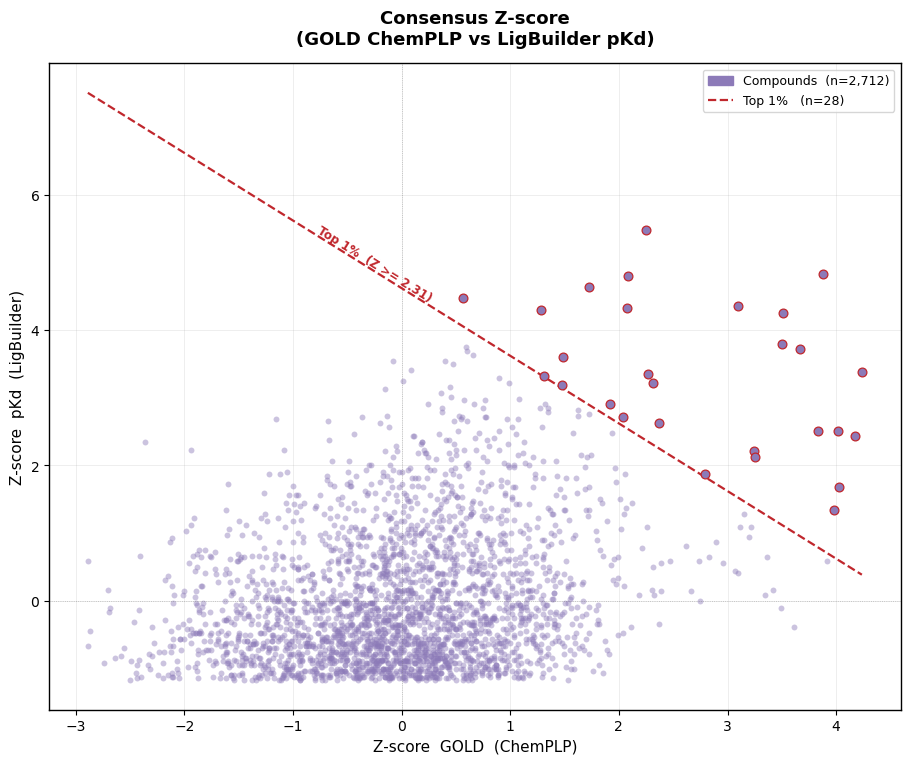

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

# -- BuPu colors ---------------------------------------------------------------
cmap       = plt.cm.BuPu
COLOR_PTS  = cmap(0.58)
TOP_EDGE   = "#C0272D"

# -- Subsets -------------------------------------------------------------------
threshold = df_ranked['consensus_z'].quantile(0.99)
top1      = df_ranked[df_ranked['consensus_z'] >= threshold]

# -- Figure --------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))

# Base points
ax.scatter(df_ranked['z_gold'], df_ranked['z_pkd'],
           color=COLOR_PTS, s=18, alpha=0.45, linewidths=0, rasterized=True)

# Top 1% highlighted
ax.scatter(top1['z_gold'], top1['z_pkd'],
           color=COLOR_PTS, s=40, alpha=1.0,
           edgecolors=TOP_EDGE, linewidths=0.9, zorder=5)

# Z = 0 reference lines
ax.axhline(0, color='gray', linewidth=0.6, linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linewidth=0.6, linestyle=':', alpha=0.5)

# Diagonal cutoff line
x_diag = np.linspace(df_ranked['z_gold'].min(), df_ranked['z_gold'].max(), 300)
y_diag = 2 * threshold - x_diag
ax.plot(x_diag, y_diag, color=TOP_EDGE, linewidth=1.6, linestyle='--', alpha=1.0, zorder=3)

# Real angle in display coordinates
plt.tight_layout()
fig.canvas.draw()
p1 = ax.transData.transform([x_diag[0],  y_diag[0]])
p2 = ax.transData.transform([x_diag[-1], y_diag[-1]])
angle = np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0]))

# Label: anchored with a perpendicular offset above the line
mid = len(x_diag) // 2
perp = 1
ax.text(x_diag[mid] - perp, y_diag[mid] + perp,
        f'  Top 1%  (Z >= {threshold:.2f})',
        color=TOP_EDGE, fontsize=8.5, ha='center', va='bottom', fontweight='bold',
        rotation=angle, rotation_mode='anchor', zorder=4)

# -- Styling -------------------------------------------------------------------
ax.set_xlabel('Z-score  GOLD  (ChemPLP)', fontsize=11)
ax.set_ylabel('Z-score  pKd  (LigBuilder)', fontsize=11)
ax.set_title('Consensus Z-score\n(GOLD ChemPLP vs LigBuilder pKd)', fontsize=13, pad=14, fontweight='bold')

# Full box (all spines visible)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)
    spine.set_color('black')

# Subtle grid behind the points
ax.grid(True, linestyle='-', linewidth=0.5, alpha=0.3)
ax.set_axisbelow(True)

# -- Legend --------------------------------------------------------------------
patch_pts = mpatches.Patch(color=COLOR_PTS, label=f'Compounds  (n={len(df_ranked):,})')
line_top  = mlines.Line2D([], [], color=TOP_EDGE, linewidth=1.6, linestyle='--',
                           label=f'Top 1%   (n={len(top1):,})')

ax.legend(handles=[patch_pts, line_top],
          frameon=True, fontsize=9, loc='upper right')

plt.savefig('consensus_zscore_scatter.png', dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
cols = [
    'ID', 'SMILES', 'Name', 'Formula', 'MW', 'LogP',
    'pKd', 'ChemPLP', 'z_pkd', 'z_gold', 'consensus_z',
    'SA_Score', 'Structure', 'Synthesize', 'Chemical', 'Dataset'
]
cols = [c for c in cols if c in df_ranked.columns]

top1_export = top1[cols].sort_values('consensus_z', ascending=False).reset_index(drop=True)
top1_export.to_csv('top1pct_consensus_zscore.csv', index=False)

print(f"Saved {len(top1_export)} compounds -> top1pct_consensus_zscore.csv")
top1_export.head()

In [ ]:
df_ranked[cols].to_csv('all_consensus_zscore.csv', index=False)
print(f"Saved {len(df_ranked)} compounds -> all_consensus_zscore.csv")

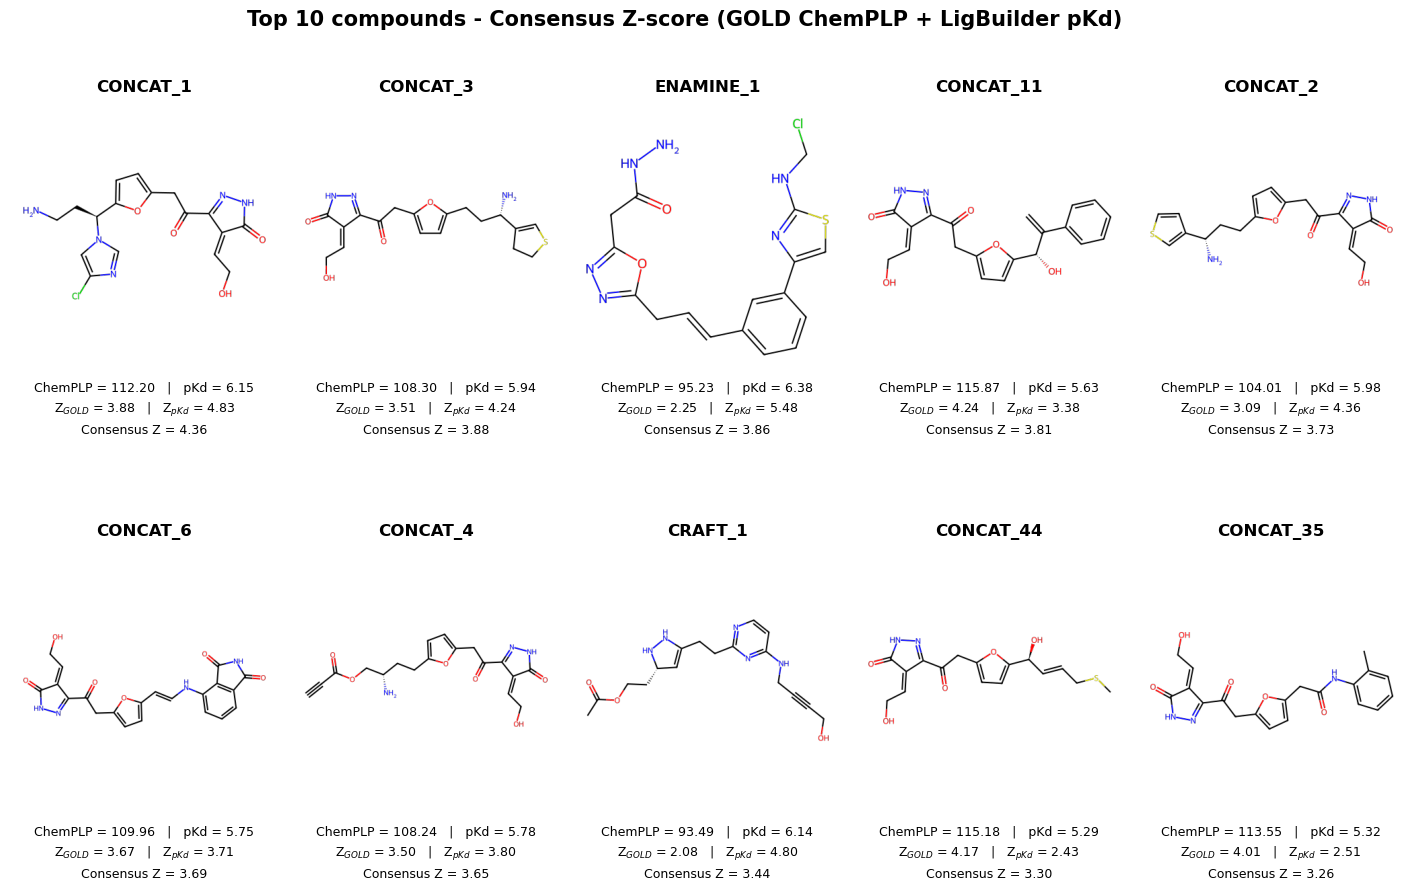

In [14]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D
import matplotlib.image as mpimg
import io

# ── Top 10 compounds by consensus Z-score ─────────────────────────────────────
top10 = df_ranked.head(10).reset_index(drop=True)

N_COLS, N_ROWS = 5, 2
PANEL = 400  # pixels per molecule panel

def draw_mol(smiles, size=PANEL):
    """Render a SMILES string to an RGB image array."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    Chem.rdDepictor.Compute2DCoords(mol)
    drawer = rdMolDraw2D.MolDraw2DCairo(size, size)
    opts = drawer.drawOptions()
    opts.clearBackground = False
    opts.bondLineWidth = 2
    rdMolDraw2D.PrepareAndDrawMolecule(drawer, mol)
    drawer.FinishDrawing()
    return mpimg.imread(io.BytesIO(drawer.GetDrawingText()), format='png')

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(3.6 * N_COLS, 4.4 * N_ROWS))
axes = axes.ravel()

for ax, (_, row) in zip(axes, top10.iterrows()):
    img = draw_mol(row['SMILES'])
    if img is not None:
        ax.imshow(img, aspect='equal')
    else:
        ax.text(0.5, 0.5, 'invalid SMILES', ha='center', va='center', fontsize=9)

    # Bold ID above the structure
    ax.set_title(row['ID'], fontsize=12, fontweight='bold', pad=8)

    # Scores below the structure
    ax.set_xlabel(
        f"ChemPLP = {row['ChemPLP']:.2f}   |   pKd = {row['pKd']:.2f}\n"
        f"Z$_{{GOLD}}$ = {row['z_gold']:.2f}   |   Z$_{{pKd}}$ = {row['z_pkd']:.2f}\n"
        f"Consensus Z = {row['consensus_z']:.2f}",
        fontsize=9, labelpad=8, linespacing=1.5
    )

    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# Hide unused panels
for ax in axes[len(top10):]:
    ax.axis('off')

fig.suptitle('Top 10 compounds - Consensus Z-score (GOLD ChemPLP + LigBuilder pKd)',
             fontsize=15, fontweight='bold', y=0.98)
# Explicit spacing: equal-aspect images leave the axes box larger than the drawing,
# so tight_layout alone lets the score labels collide with the next row's titles.
fig.subplots_adjust(top=0.90, bottom=0.04, hspace=0.42, wspace=0.05)
plt.savefig('top10_consensus_structures.png', dpi=600, bbox_inches='tight')
plt.show()